# 23 · Segmentación de personas cuidadoras (clases latentes, ENASIC 2022)

**Unidad:** Herramientas y Técnicas Avanzadas (modelo) · insumo para Analítica para los Negocios.
**Estado:** exploratorio, sin doble revisión. Ninguna cifra de este notebook se cita en el informe ni en la presentación hasta que la revise alguien distinto a quien lo produjo.

## Para qué decisión existe
El programa (opción C) ofrece **relevo por horas**. La regla de focalización vigente es «cuida 40 h o más» (notebooks 11, 21 y 22: ningún modelo la supera para «algún daño»).
La pregunta de este notebook es otra: **¿hay perfiles de cuidadoras que necesiten algo distinto al relevo por horas?** Por ejemplo, alguien que no cuida tantas horas pero no puede sola con la tarea física, o que necesita capacitación.
Si existen, el programa tendría que ofrecer más de un formato. Si no existen, la segmentación por horas (script 12) basta.

## Qué representa una fila
| Concepto | Valor |
|---|---|
| Tabla | TPOB_CUI (población cuidadora) |
| Unidad | persona cuidadora de 15 años o más |
| Universo | cuida a una persona con discapacidad o dependencia (`PB_CDISC`) o a una de 60+ sin discapacidad (`PB_C60MA`) |
| Clave | `LLAVEMOD` |
| Independencia | **no**: las personas están agrupadas en UPM dentro de estratos |
| Factor | `FAC_CUI` |
| Diseño | estratos `EST_DIS`, conglomerados `UPM_DIS`, varianza por linealización de Taylor |

## Reglas fijadas antes de ajustar el modelo
1. **Indicadores del modelo = situación de cuidado, no daño.** Si el daño entrara al modelo, las clases «con daño» serían una tautología. El daño, la búsqueda de servicios, la preferencia y los datos sociodemográficos solo se usan **después**, para describir y validar las clases.
2. **Solo indicadores comparables entre los dos bloques del cuestionario.** Las actividades básicas (`P6_2_*`) solo se preguntan en el bloque de discapacidad, y en el de 60+ casi nadie contesta su equivalente (`P6_22_*`, 23 de 407; bitácora del 20 oct, 21:45). Si entraran, el modelo redescubriría el bloque del cuestionario. Por lo mismo, «a quién cuida» no es indicador: es la segmentación a priori contra la que se compara.
3. **Elección del número de clases (k):** el k con menor BIC, con dos condiciones: la clase más chica pesa al menos 10 % y tiene al menos 80 casos en muestra. Si dos k quedan a menos de 10 puntos de BIC, se elige el menor (parsimonia).
4. **Alternativas simples obligatorias:** (a) intensidad en tres cortes, como el script 12; (b) bloque × «40 h o más» (cuatro grupos a priori); (c) una regla escrita a mano que imita las clases con conteos de respuestas.
5. **Validación fuera de muestra:** particiones agrupadas por UPM. Se mide cuánto separa cada segmentación desenlaces que **no** entraron al modelo.
6. **No se guarda la clase de cada persona** en ningún archivo. Solo salen agregados.

## Qué NO permite afirmar (se repite al final)
Nada sobre la CDMX (encuesta nacional). Tampoco que una clase «cause» daño, ni que un formato de apoyo funcione para una clase. Las clases son una partición útil o no útil, no tipos naturales.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

SEMILLA = 20261020
RAIZ = Path(".")  # se ejecuta desde Analysis/
DATOS = RAIZ / "datos" / "enasic"
RES = RAIZ / "resultados"
FIG = RAIZ / "figuras"
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
Z90 = stats.norm.ppf(0.95)

# Paleta categórica en orden fijo (slots 1-4, validada para daltonismo en pares adyacentes) y grises de referencia
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GRIS = "#8a8984"
TINTA = "#0b0b0b"
TINTA2 = "#52514e"
plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb6", "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
    "ytick.color": TINTA2, "axes.titleweight": "bold", "axes.titlesize": 11,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

## 1. Carga y universo
Se usa la misma definición de horas que los notebooks 11, 21 y 22: **suma de `P6_7` (bloque de discapacidad) y `P6_26` (bloque 0-17 / 60+)**. Consecuencia que se declara: `P6_26` incluye las horas dedicadas a menores cuando la persona también cuida niñas o niños.

In [2]:
pc = pd.read_csv(DATOS / "conjunto_de_datos_tpob_cui_enasic_2022" / "conjunto_de_datos" /
                 "conjunto_de_datos_tpob_cui_enasic_2022.csv", low_memory=False)
pc.columns = pc.columns.str.lower()
hog = pd.read_csv(DATOS / "conjunto_de_datos_thogar_enasic_2022" / "conjunto_de_datos" /
                  "conjunto_de_datos_thogar_ensasic_2022.csv", low_memory=False)
hog.columns = hog.columns.str.lower()

u = pc[(pc.pb_cdisc == 1) | (pc.pb_c60ma == 1)].copy()
for c in u.columns:
    if c.startswith(("p5_", "p6_", "p7_")):
        u[c] = pd.to_numeric(u[c], errors="coerce")
u = u.merge(hog[["llavehog", "p3a_4"]], on="llavehog", how="left")
u = u.reset_index(drop=True)

DISC = (u.pb_cdisc == 1).values
W = u.fac_cui.values.astype(float)
WN = W / W.mean()            # pesos normalizados a media 1 (suma = n) para el modelo
EST = u.est_dis.values
UPM = u.upm_dis.values
HORAS = (u.p6_7.fillna(0) + u.p6_26.fillna(0)).values
print(f"Personas cuidadoras en el universo: {len(u)}  (bloque discapacidad {DISC.sum()}, solo 60+ {(~DISC).sum()})")
print(f"Total expandido: {W.sum():,.0f}")

Personas cuidadoras en el universo: 1043  (bloque discapacidad 636, solo 60+ 407)
Total expandido: 6,223,684


## 2. Estimador con diseño muestral y controles de reproducción
Proporción ponderada con varianza por linealización de Taylor (estratos y UPM). Los dominios se estiman con indicadora, sin recortar la muestra. Estratos con una sola UPM en el universo (19 de 139) no aportan varianza; es la misma convención del notebook 11.
Criterios de precisión del INEGI: alta si CV < 15 %, moderada entre 15 % y 30 %, baja si CV ≥ 30 %.

In [3]:
def svy_prop(y, dom=None, w=W, est=EST, upm=UPM):
    """Devuelve (p, ee, n_dominio, n_si). y puede tener NaN (se excluyen del dominio)."""
    y = np.asarray(y, float)
    d = np.ones_like(w) if dom is None else np.asarray(dom, float)
    ok = ~np.isnan(y)
    d = d * ok
    y = np.nan_to_num(y)
    N = (w * d).sum()
    if N == 0:
        return np.nan, np.nan, 0, 0
    p = (w * d * y).sum() / N
    z = w * d * (y - p) / N
    t = pd.DataFrame({"z": z, "h": est, "c": upm}).groupby(["h", "c"]).z.sum().reset_index()
    v = 0.0
    for _, g in t.groupby("h"):
        n = len(g)
        if n > 1:
            v += n / (n - 1) * ((g.z - g.z.mean()) ** 2).sum()
    return p, np.sqrt(v), int(d.sum()), int((d * y).sum())


def precision(cv):
    if np.isnan(cv):
        return "no estimable"
    return "alta" if cv < 15 else ("moderada" if cv < 30 else "baja")


def fila(y, dom=None):
    p, se, n, ns = svy_prop(y, dom)
    cv = 100 * se / p if p > 0 else np.nan
    return dict(pct=100 * p, li90=100 * (p - Z90 * se), ls90=100 * (p + Z90 * se),
                cv=cv, precision=precision(cv), n_muestra=n, n_si=ns)


# Definiciones de desenlace idénticas a las de los notebooks 07, 11, 21 y 22
def ambos(a, b):
    return ((u[a] == 1) | (u[b] == 1)).values

SALUD = ambos("p6_11_1", "p6_30_1")
CANSANCIO = ambos("p6_11_3", "p6_30_3")
SUENO = ambos("p6_11_6", "p6_30_6")
ENFERMEDAD = ambos("p6_11_7", "p6_30_7")
IMPOSIB = ambos("p6_12_1", "p6_31_1")
DEJO = ambos("p6_12_2", "p6_31_2")
REDUJO = ambos("p6_12_5", "p6_31_5")
DANO = SALUD | CANSANCIO | SUENO | ENFERMEDAD | IMPOSIB | DEJO | REDUJO
LABORAL = IMPOSIB | DEJO | REDUJO

controles = pd.DataFrame([
    ("Universo (n)", len(u), 1043),
    ("Cuida 40 h o más (%)", fila(HORAS >= 40)["pct"], 40.72),
    ("Algún daño (%)", fila(DANO)["pct"], 62.16),
    ("Algún daño, casos", int(DANO.sum()), 631),
    ("Algún daño, LI 90 %", fila(DANO)["li90"], 58.77),
    ("Algún daño, LS 90 %", fila(DANO)["ls90"], 65.55),
    ("Salud física deteriorada (%)", fila(SALUD)["pct"], 23.46),
    ("Salud física, casos", int(SALUD.sum()), 222),
], columns=["control", "este_notebook", "referencia"])
controles["coincide"] = np.isclose(controles.este_notebook.astype(float), controles.referencia, atol=0.01)
display(controles.round(2))
assert controles.coincide.all(), "No se reproducen las cifras de referencia: revisar definiciones antes de seguir"

,control,este_notebook,referencia,coincide
0,Universo (n),1043.00,1043.00,True
1,Cuida 40 h o más (%),40.72,40.72,True
2,Algún daño (%),62.16,62.16,True
3,"Algún daño, casos",631.00,631.00,True
4,"Algún daño, LI 90 %",58.77,58.77,True
5,"Algún daño, LS 90 %",65.55,65.55,True
6,Salud física deteriorada (%),23.46,23.46,True
7,"Salud física, casos",222.00,222.00,True


Referencias: 1043, 40.7 % y 62.2 % (IC 58.77–65.55) de `11_objetivo_resumen.csv`; 23.5 % y 222 casos de la bitácora del 20 oct (10:40).

## 3. Indicadores del modelo (situación de cuidado)
| Indicador | Pregunta (bloque discapacidad / bloque 60+) | Codificación |
|---|---|---|
| Horas | P6.7 + P6.26 | <20, 20–39, 40–79, 80+ |
| Cuida también a menores | PB_C0005 o PB_C0617 | sí/no |
| Le falta fuerza física | P6.9.1 / P6.28.1 | sí/no (8 «no aplica» = faltante) |
| La persona no coopera | P6.9.2 / P6.28.2 | sí/no |
| Necesitaría capacitación | P6.9.3 / P6.28.3 | sí/no |
| Requiere que otra persona le apoye | P6.9.4 / P6.28.4 | sí/no |
| Insatisfecha con la ayuda que recibe | P6.39.3 | sí/no |
| Motivo para cuidar | P6.38 | iniciativa propia / decisión familiar o petición / obligación o «la única que podía» |

Si la persona está en los dos bloques, las dificultades se toman del bloque de discapacidad (P6.9).
**Advertencia declarada:** «le falta fuerza física» y «requiere apoyo» pueden ser consecuencia de cuidar, y se parecen al daño a la salud física (bitácora del 20 oct). Por eso la sección 9 repite todo sin esas dos variables.
Se descartó «recibe apoyo económico de la familia» (P6.8 / P6.27): solo 37 casos dicen que sí.

In [4]:
def bloque(a, b):
    return pd.Series(np.where(DISC, u[a], u[b]))

X = pd.DataFrame(index=u.index)
X["horas"] = pd.cut(HORAS, [0, 19.99, 39.99, 79.99, 1e9], labels=False)
X["menores"] = ((u.pb_c0005 == 1) | (u.pb_c0617 == 1)).astype(int)
for nombre, (a, b) in {"fuerza": ("p6_9_1", "p6_28_1"), "nocoopera": ("p6_9_2", "p6_28_2"),
                       "capacitacion": ("p6_9_3", "p6_28_3"), "reqapoyo": ("p6_9_4", "p6_28_4")}.items():
    X[nombre] = bloque(a, b).replace(8, np.nan).map({1: 1, 2: 0})
X["insatisfecha"] = (u.p6_39_3 == 2).astype(int)
X["motivo"] = u.p6_38.map({5: 0, 2: 1, 4: 1, 1: 2, 3: 2})

ETIQ = {
    "horas": "Horas de cuidado", "menores": "Cuida también a menores",
    "fuerza": "Le falta fuerza física", "nocoopera": "La persona no coopera",
    "capacitacion": "Necesitaría capacitación", "reqapoyo": "Requiere que otra persona le apoye",
    "insatisfecha": "Insatisfecha con la ayuda que recibe", "motivo": "Motivo para cuidar",
}
CATS = {"horas": ["<20 h", "20–39 h", "40–79 h", "80 h o más"],
        "motivo": ["Iniciativa propia", "Decisión familiar o petición", "Obligación o «la única que podía»"]}
faltantes = X.isna().sum().rename("faltantes").to_frame()
faltantes["% de la muestra"] = (100 * faltantes.faltantes / len(X)).round(1)
display(faltantes)
XA = X.fillna(-1).astype(int).values   # -1 = faltante; el modelo lo omite en la verosimilitud

,faltantes,% de la muestra
horas,0,0.0
menores,0,0.0
fuerza,25,2.4
nocoopera,31,3.0
capacitacion,21,2.0
reqapoyo,6,0.6
insatisfecha,0,0.0
motivo,0,0.0


## 4. Modelo de clases latentes ponderado
Se programa el algoritmo EM directamente (unas 40 líneas) para que sea transparente y rápido en las validaciones. Los faltantes se omiten en la verosimilitud (supuesto: faltan al azar dado la clase). Los pesos `FAC_CUI` se normalizan a media 1, así que el BIC usa n = 1043.
Control: la verosimilitud coincide con la del paquete StepMix 3.0 (k = 2: −5013.5; k = 3: −4974.0; corrido aparte durante el desarrollo).

In [5]:
def lca_fit(Xi, w, k, n_init=30, max_iter=2000, tol=1e-9, seed=SEMILLA, floor=1e-10):
    rng = np.random.default_rng(seed)
    n, J = Xi.shape
    C = [int(Xi[:, j].max()) + 1 for j in range(J)]
    obs = [Xi[:, j] >= 0 for j in range(J)]
    oh = [np.eye(C[j])[np.where(obs[j], Xi[:, j], 0)] * obs[j][:, None] for j in range(J)]
    mejor = None
    for _ in range(n_init):
        r = rng.dirichlet(np.ones(k), size=n)
        ll_ant = -np.inf
        for it in range(max_iter):
            wr = r * w[:, None]
            pi = wr.sum(0) / wr.sum()
            theta = []
            for j in range(J):
                num = wr.T @ oh[j]
                den = (wr * obs[j][:, None]).sum(0)[:, None]
                theta.append(np.clip(num / np.maximum(den, floor), floor, 1))
            logp = np.tile(np.log(pi), (n, 1))
            for j in range(J):
                logp += oh[j] @ np.log(theta[j]).T
            mx = logp.max(1, keepdims=True)
            lse = mx[:, 0] + np.log(np.exp(logp - mx).sum(1))
            ll = (w * lse).sum()
            r = np.exp(logp - lse[:, None])
            if ll - ll_ant < tol * abs(ll):
                break
            ll_ant = ll
        if mejor is None or ll > mejor["ll"]:
            mejor = dict(pi=pi, theta=theta, ll=ll, resp=r, C=C)
    npar = (k - 1) + k * sum(c - 1 for c in C)
    mejor.update(k=k, npar=npar, bic=-2 * mejor["ll"] + npar * np.log(w.sum()),
                 aic=-2 * mejor["ll"] + 2 * npar)
    r = mejor["resp"]
    mejor["entropia"] = (1 - (-(w[:, None] * r * np.log(r + 1e-300)).sum()) / (w.sum() * np.log(k))) if k > 1 else np.nan
    return mejor


def lca_posterior(m, Xi):
    n, J = Xi.shape
    logp = np.tile(np.log(m["pi"]), (n, 1))
    for j in range(J):
        o = Xi[:, j] >= 0
        logp[o] += np.log(m["theta"][j][:, Xi[o, j]]).T
    mx = logp.max(1, keepdims=True)
    r = np.exp(logp - mx)
    return r / r.sum(1, keepdims=True)


def ordenar(m):
    """Orden fijo de clases para que las etiquetas no cambien entre corridas:
    primero la clase con más dificultad en la tarea (requiere apoyo), luego por horas medias."""
    k = m["k"]
    j_req = list(X.columns).index("reqapoyo")
    j_h = list(X.columns).index("horas")
    req = m["theta"][j_req][:, 1]
    hmed = m["theta"][j_h] @ np.arange(4)
    orden = sorted(range(k), key=lambda c: (-round(req[c], 1), -hmed[c]))
    m["pi"] = m["pi"][orden]
    m["theta"] = [t[orden] for t in m["theta"]]
    m["resp"] = m["resp"][:, orden]
    return m

## 5. ¿Cuántas clases? Ajuste, tamaño y estabilidad
Estabilidad (réplicas con tolerancia 1e-6, 5 arranques y máx. 500 iteraciones por costo de cómputo; el ajuste principal usa 1e-9 y 30 arranques): 100 réplicas bootstrap de UPM dentro de estrato (el peso de cada persona se multiplica por las veces que sale su UPM). En cada réplica se reajusta el modelo, se asigna la muestra completa y se compara con la asignación original con el índice de Rand ajustado (ARI: 1 = misma partición, 0 = azar).

In [6]:
modelos = {}
filas_k = []
for k in range(1, 7):
    m = ordenar(lca_fit(XA, WN, k)) if k > 1 else lca_fit(XA, WN, k)
    modelos[k] = m
    lab = m["resp"].argmax(1)
    tam = [WN[lab == c].sum() / WN.sum() for c in range(k)]
    nmin = min(int((lab == c).sum()) for c in range(k))
    filas_k.append(dict(k=k, loglik=m["ll"], parametros=m["npar"], BIC=m["bic"], AIC=m["aic"],
                        entropia=m["entropia"], clase_menor_pct=100 * min(tam), clase_menor_n=nmin))
sel = pd.DataFrame(filas_k)
sel["cumple_tamano"] = (sel.clase_menor_pct >= 10) & (sel.clase_menor_n >= 80)


def bootstrap_upm(rng):
    """Multiplicador de peso por persona: UPM remuestreadas con reemplazo dentro de cada estrato."""
    mult = np.zeros(len(u))
    for h, upms in pd.Series(UPM).groupby(EST):
        uu = np.unique(upms.values)
        elegidas = rng.choice(uu, size=len(uu), replace=True)
        cuenta = pd.Series(elegidas).value_counts()
        mask = np.isin(UPM, cuenta.index) & (EST == h)
        mult[mask] = pd.Series(UPM[mask]).map(cuenta).values
    return mult


rng = np.random.default_rng(SEMILLA)
B = 100
ari = {k: [] for k in range(2, 6)}
for b in range(B):
    mult = bootstrap_upm(rng)
    wb = WN * mult
    for k in range(2, 6):
        mb = lca_fit(XA, wb / wb.mean(), k, n_init=5, tol=1e-6, max_iter=500, seed=SEMILLA + b)
        ari[k].append(adjusted_rand_score(modelos[k]["resp"].argmax(1), lca_posterior(mb, XA).argmax(1)))
sel["ARI_mediana"] = sel.k.map({k: np.median(v) for k, v in ari.items()})
sel["ARI_p10"] = sel.k.map({k: np.percentile(v, 10) for k, v in ari.items()})
display(sel.round(3))

,k,loglik,parametros,BIC,AIC,entropia,clase_menor_pct,clase_menor_n,cumple_tamano,ARI_mediana,ARI_p10
0,1,-5227.316,11,10531.080,10476.631,NaN,100.000,1043,True,NaN,NaN
1,2,-5013.471,23,10186.788,10072.941,0.692,25.688,313,True,0.911,0.820
2,3,-4973.976,35,10191.196,10017.951,0.630,25.798,256,True,0.661,0.439
3,4,-4953.631,47,10233.904,10001.261,0.668,10.136,100,True,0.506,0.342
4,5,-4932.811,59,10275.663,9983.622,0.694,1.051,8,False,0.490,0.287
5,6,-4911.284,71,10316.008,9964.568,0.733,1.051,8,False,NaN,NaN


### Aplicación de la regla del paso 3

In [7]:
candidatos = sel[(sel.k > 1) & sel.cumple_tamano].copy()
bic_min = candidatos.BIC.min()
empatados = candidatos[candidatos.BIC - bic_min < 10]
K = int(empatados.k.min())
K_ALT = 3 if K != 3 else 2
print(f"k con menor BIC entre los que cumplen tamaño: {int(candidatos.loc[candidatos.BIC.idxmin(), 'k'])}")
print(f"k dentro de 10 puntos de BIC: {empatados.k.tolist()}  ->  se elige k = {K} (parsimonia)")
print(f"Se reporta además k = {K_ALT} como solución secundaria (diferencia de BIC "
      f"{abs(sel.loc[sel.k == K_ALT, 'BIC'].item() - sel.loc[sel.k == K, 'BIC'].item()):.1f}).")
sel.round(4).to_csv(RES / "23_seg_seleccion_k.csv", index=False, encoding="utf-8-sig")

k con menor BIC entre los que cumplen tamaño: 2
k dentro de 10 puntos de BIC: [2, 3]  ->  se elige k = 2 (parsimonia)
Se reporta además k = 3 como solución secundaria (diferencia de BIC 4.4).


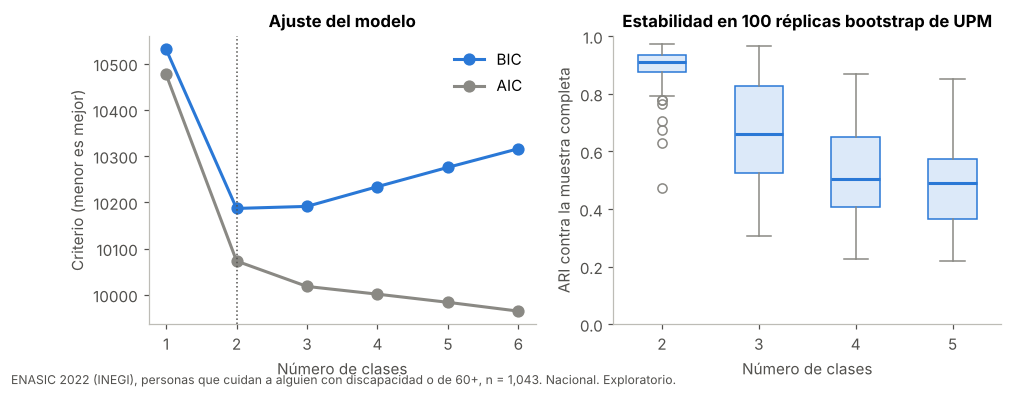

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(sel.k, sel.BIC, "-o", color=COL[0], lw=2, ms=7, label="BIC")
ax[0].plot(sel.k, sel.AIC, "-o", color=GRIS, lw=2, ms=7, label="AIC")
ax[0].axvline(K, color=TINTA2, lw=1, ls=":")
ax[0].set_xlabel("Número de clases"); ax[0].set_ylabel("Criterio (menor es mejor)")
ax[0].set_title("Ajuste del modelo"); ax[0].legend(frameon=False)
ks = list(ari)
ax[1].boxplot([ari[k] for k in ks], positions=ks, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor="#dce9f9", edgecolor=COL[0]), medianprops=dict(color=COL[0], lw=2),
              whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS), flierprops=dict(markeredgecolor=GRIS))
ax[1].set_ylim(0, 1); ax[1].set_xlabel("Número de clases"); ax[1].set_ylabel("ARI contra la muestra completa")
ax[1].set_title("Estabilidad en 100 réplicas bootstrap de UPM")
fig.text(0, -0.05, "ENASIC 2022 (INEGI), personas que cuidan a alguien con discapacidad o de 60+, n = 1,043. Nacional. Exploratorio.",
         fontsize=8, color=TINTA2)
fig.savefig(FIG / "f27_seg_seleccion_k.png"); plt.show()

## 6. Perfil de las clases (indicadores del modelo)
Las clases se asignan por probabilidad máxima. La tabla da, para cada clase, el % ponderado de cada respuesta con IC 90 % por diseño, tratando la clase como dominio. **Esto subestima la incertidumbre**: ignora que la clase misma se estimó (ver entropía y la sección 9).

In [9]:
def asignar(k):
    return modelos[k]["resp"].argmax(1)


def nombre_clases(k):
    """Nombres descriptivos que se asignan mirando los perfiles; se revisan si el perfil cambia."""
    if k == 2:
        return ["Dificultad en la tarea", "Sin dificultad declarada"]
    if k == 3:
        return ["Dificultad en la tarea", "Alta intensidad sin dificultad", "Baja intensidad sin dificultad"]
    return [f"Clase {c+1}" for c in range(k)]


def perfiles(k):
    lab = asignar(k)
    nombres = nombre_clases(k)
    out = []
    for c in range(k):
        dom = lab == c
        tam = fila(dom.astype(float))
        out.append(dict(k=k, clase=c + 1, nombre=nombres[c], variable="tamano", categoria="% de las cuidadoras",
                        **tam, total_expandido=W[dom].sum()))
        for v in X.columns:
            cats = CATS.get(v, ["sí"])
            for i, cat in enumerate(cats):
                val = i if v in CATS else 1
                y = np.where(X[v].isna(), np.nan, (X[v] == val).astype(float))
                f = fila(y, dom)
                pt, *_ = svy_prop(y)
                out.append(dict(k=k, clase=c + 1, nombre=nombres[c], variable=v, categoria=cat, **f,
                                pct_total=100 * pt))
    return pd.DataFrame(out)

perf = pd.concat([perfiles(K), perfiles(K_ALT)], ignore_index=True)

# Control de nombres: los nombres de k = 3 suponen que la clase 2 cuida más horas que la 3
_h = perf[(perf.k == 3) & (perf.variable == "horas") & perf.categoria.isin(["40–79 h", "80 h o más"])].groupby("clase").pct.sum()
assert _h.loc[2] > _h.loc[3], "Los nombres de las clases de k = 3 no corresponden al perfil: revisar nombre_clases()"
cols = ["k", "clase", "nombre", "variable", "categoria", "pct", "li90", "ls90", "cv", "precision", "n_muestra", "pct_total"]
display(perf[perf.k == K][cols].round(1))

,k,clase,nombre,variable,categoria,pct,li90,ls90,cv,precision,n_muestra,pct_total
0,2,1,Dificultad en la tarea,tamano,% de las cuidadoras,25.7,22.1,29.3,8.5,alta,1043,NaN
1,2,1,Dificultad en la tarea,horas,<20 h,26.7,21.5,32.0,12.0,alta,313,31.6
2,2,1,Dificultad en la tarea,horas,20–39 h,26.9,21.4,32.3,12.3,alta,313,27.7
3,2,1,Dificultad en la tarea,horas,40–79 h,29.1,23.1,35.0,12.5,alta,313,29.8
4,2,1,Dificultad en la tarea,horas,80 h o más,17.3,12.8,21.8,15.8,moderada,313,10.9
5,2,1,Dificultad en la tarea,menores,sí,28.3,22.6,34.1,12.4,alta,313,25.2
6,2,1,Dificultad en la tarea,fuerza,sí,69.9,64.7,75.1,4.5,alta,310,27.4
7,2,1,Dificultad en la tarea,nocoopera,sí,34.6,28.2,40.9,11.2,alta,308,13.7
8,2,1,Dificultad en la tarea,capacitacion,sí,58.1,51.8,64.3,6.5,alta,307,17.7
9,2,1,Dificultad en la tarea,reqapoyo,sí,86.1,81.9,90.4,3.0,alta,312,28.3


In [10]:
display(perf[perf.k == K_ALT][cols].round(1))

,k,clase,nombre,variable,categoria,pct,li90,ls90,cv,precision,n_muestra,pct_total
28,3,1,Dificultad en la tarea,tamano,% de las cuidadoras,25.8,22.2,29.4,8.5,alta,1043,NaN
29,3,1,Dificultad en la tarea,horas,<20 h,27.1,21.7,32.5,12.2,alta,312,31.6
30,3,1,Dificultad en la tarea,horas,20–39 h,26.4,21.0,31.8,12.4,alta,312,27.7
31,3,1,Dificultad en la tarea,horas,40–79 h,28.9,22.9,34.9,12.6,alta,312,29.8
32,3,1,Dificultad en la tarea,horas,80 h o más,17.6,13.1,22.1,15.5,moderada,312,10.9
33,3,1,Dificultad en la tarea,menores,sí,28.4,22.7,34.1,12.3,alta,312,25.2
34,3,1,Dificultad en la tarea,fuerza,sí,70.8,65.6,75.9,4.4,alta,308,27.4
35,3,1,Dificultad en la tarea,nocoopera,sí,35.3,28.8,41.8,11.3,alta,306,13.7
36,3,1,Dificultad en la tarea,capacitacion,sí,57.6,51.3,63.9,6.6,alta,305,17.7
37,3,1,Dificultad en la tarea,reqapoyo,sí,85.4,80.9,89.9,3.2,alta,310,28.3


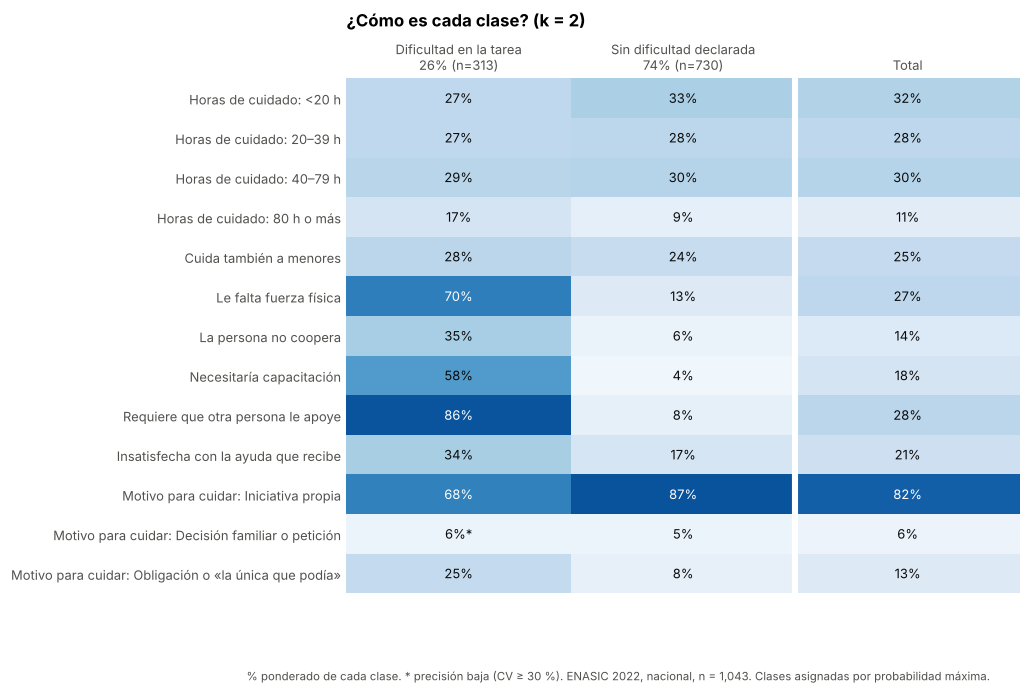

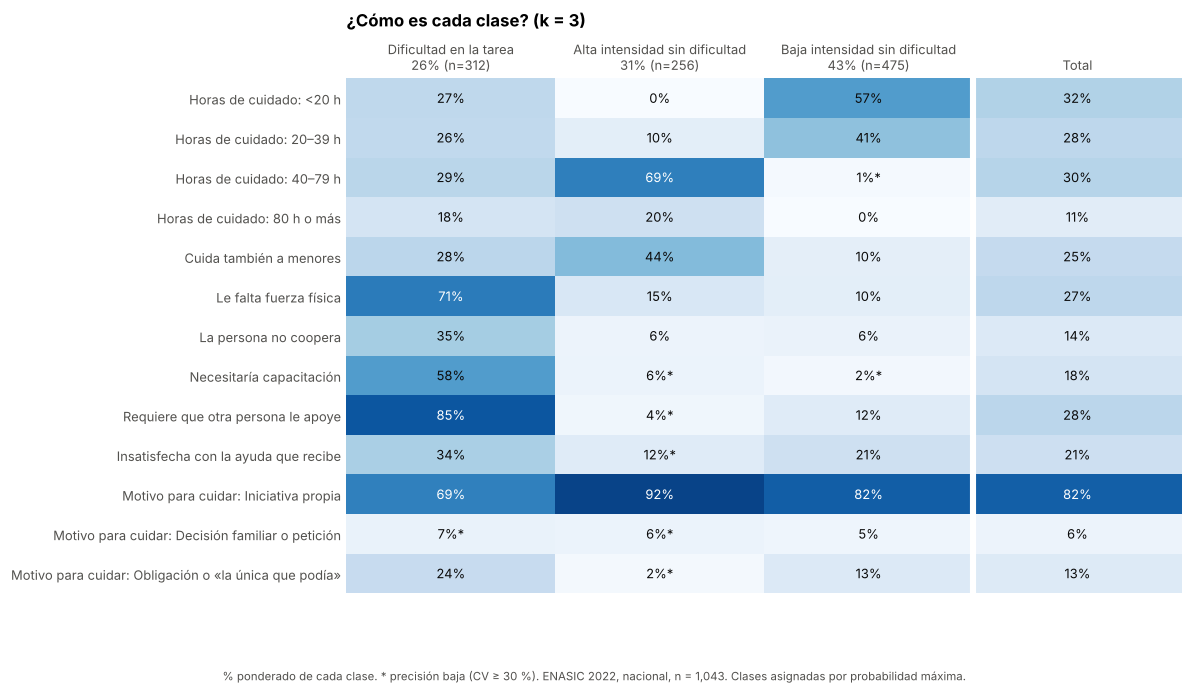

In [11]:
def heatmap_perfil(k, archivo):
    p = perf[(perf.k == k) & (perf.variable != "tamano")].copy()
    p["renglon"] = np.where(p.variable.isin(list(CATS)), p.variable.map(ETIQ) + ": " + p.categoria, p.variable.map(ETIQ))
    tabla = p.pivot_table(index="renglon", columns="clase", values="pct", sort=False)
    prec = p.pivot_table(index="renglon", columns="clase", values="precision", aggfunc="first", sort=False)
    tot = p.drop_duplicates("renglon").set_index("renglon").pct_total
    tam = perf[(perf.k == k) & (perf.variable == "tamano")].set_index("clase")
    nombres = nombre_clases(k)
    fig, ax = plt.subplots(figsize=(2.2 + 1.9 * (k + 1), 0.36 * len(tabla) + 1.4))
    datos = np.column_stack([tabla.values, tot.values])
    im = ax.imshow(datos, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    for i in range(datos.shape[0]):
        for j in range(datos.shape[1]):
            v = datos[i, j]
            baja = j < k and prec.values[i, j] == "baja"
            ax.text(j, i, f"{v:.0f}%" + ("*" if baja else ""), ha="center", va="center", fontsize=8.5,
                    color="white" if v > 60 else TINTA)
    enc = [f"{nombres[c]}\n{tam.loc[c+1,'pct']:.0f}% (n={tam.loc[c+1,'n_si']})" for c in range(k)] + ["Total"]
    ax.set_xticks(range(k + 1), enc, fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(tabla)), tabla.index, fontsize=8.5)
    ax.axvline(k - 0.5, color="white", lw=4)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(f"¿Cómo es cada clase? (k = {k})", pad=34, loc="left")
    fig.text(0.01, -0.02, "% ponderado de cada clase. * precisión baja (CV ≥ 30 %). ENASIC 2022, nacional, n = 1,043. "
             "Clases asignadas por probabilidad máxima.", fontsize=7.5, color=TINTA2)
    fig.savefig(FIG / archivo); plt.show()

heatmap_perfil(K, "f28_seg_perfiles_k2.png")
heatmap_perfil(K_ALT, "f29_seg_perfiles_k3.png")

## 7. Validación externa: ¿las clases separan cosas que no entraron al modelo?
Desenlaces y covariables por clase, con IC 90 % y la diferencia contra el resto de las cuidadoras (IC de la diferencia por linealización de la diferencia de proporciones de dominio).

In [12]:
def dif_resto(y, dom):
    """Diferencia en pp entre el dominio y su complemento, con IC 90 % por linealización."""
    y = np.asarray(y, float)
    ok = ~np.isnan(y)
    y0 = np.nan_to_num(y)
    d1 = dom * ok; d0 = (~dom) * ok
    N1 = (W * d1).sum(); N0 = (W * d0).sum()
    p1 = (W * d1 * y0).sum() / N1; p0 = (W * d0 * y0).sum() / N0
    z = W * d1 * (y0 - p1) / N1 - W * d0 * (y0 - p0) / N0
    t = pd.DataFrame({"z": z, "h": EST, "c": UPM}).groupby(["h", "c"]).z.sum().reset_index()
    v = sum(len(g) / (len(g) - 1) * ((g.z - g.z.mean()) ** 2).sum() for _, g in t.groupby("h") if len(g) > 1)
    se = np.sqrt(v)
    return 100 * (p1 - p0), 100 * (p1 - p0 - Z90 * se), 100 * (p1 - p0 + Z90 * se)


ing = pd.to_numeric(u.p3a_4, errors="coerce")
ing = ing.where(ing < 99999)                     # 99999 = no sabe; no se imputa con P3A.5
quint = pd.cut(ing, [-1, 3200, 5000, 8000, 15000, np.inf], labels=[1, 2, 3, 4, 5])  # cortes del script 04

def bin_(m):
    return np.asarray(m, float)

def con_nan(m, valido):
    return np.where(valido, np.asarray(m, float), np.nan)

DESENLACES = {
    "Algún daño por cuidar": bin_(DANO),
    "Salud física deteriorada": bin_(SALUD),
    "Cansancio": bin_(CANSANCIO),
    "Menos horas de sueño": bin_(SUENO),
    "Daño laboral (no puede, dejó o redujo trabajo)": bin_(LABORAL),
    "Insatisfecha con su tiempo libre": bin_(u.p6_39_1 == 2),
    "Buscó un servicio de cuidado (P6.42)": bin_(u.p6_42 == 1),
    "«No tuve necesidad» de buscar (P6.45.09)": con_nan(u.p6_45_09 == 1, u.p6_45_09.notna()),
    "Si contratara: en su casa (P6.46)": bin_(u.p6_46 == 1),
    "No contrataría a nadie (P6.46)": bin_(u.p6_46 == 5),
    "Acepta institución «solo unas horas» (P7.8)": bin_(u.p7_8 == 1),
}
COVARIABLES = {
    "Mujer": bin_(u.sexo == 2),
    "Edad 60+": bin_(u.edad >= 60),
    "Cuida a persona con discapacidad": bin_(DISC),
    "Cuida a discapacidad y a 60+ a la vez": bin_((u.pb_cdisc == 1) & (u.pb_c60ma == 1)),
    "Económicamente activa (CPEA)": bin_(u.cpea == 1),
    "Ingreso Q1–Q2": con_nan(quint.isin([1, 2]), quint.notna()),
    "Ingreso Q4–Q5": con_nan(quint.isin([4, 5]), quint.notna()),
    "Ingreso sin dato": bin_(quint.isna()),
}


def validacion(k):
    lab = asignar(k); nombres = nombre_clases(k); out = []
    for grupo, dic in [("desenlace", DESENLACES), ("covariable", COVARIABLES)]:
        for nombre, y in dic.items():
            pt = fila(y)["pct"]
            for c in range(k):
                dom = lab == c
                f = fila(y, dom)
                d, dli, dls = dif_resto(y, dom)
                out.append(dict(k=k, tipo=grupo, indicador=nombre, clase=c + 1, nombre=nombres[c], **f,
                                pct_total=pt, dif_pp=d, dif_li90=dli, dif_ls90=dls,
                                dif_significativa=(dli > 0) or (dls < 0)))
    return pd.DataFrame(out)

val = pd.concat([validacion(K), validacion(K_ALT)], ignore_index=True)
vcols = ["indicador", "nombre", "pct", "li90", "ls90", "precision", "pct_total", "dif_pp", "dif_li90", "dif_ls90", "dif_significativa"]
display(val[(val.k == K)][vcols].round(1))

,indicador,nombre,pct,li90,ls90,precision,pct_total,dif_pp,dif_li90,dif_ls90,dif_significativa
0,Algún daño por cuidar,Dificultad en la tarea,85.2,81.4,89.1,alta,62.2,31.0,25.5,36.5,True
1,Algún daño por cuidar,Sin dificultad declarada,54.2,50.1,58.3,alta,62.2,-31.0,-36.5,-25.5,True
2,Salud física deteriorada,Dificultad en la tarea,52.5,46.4,58.6,alta,23.5,39.1,31.8,46.3,True
3,Salud física deteriorada,Sin dificultad declarada,13.4,10.2,16.6,alta,23.5,-39.1,-46.3,-31.8,True
4,Cansancio,Dificultad en la tarea,68.7,63.0,74.3,alta,40.5,38.0,31.2,44.7,True
5,Cansancio,Sin dificultad declarada,30.7,27.0,34.5,alta,40.5,-38.0,-44.7,-31.2,True
6,Menos horas de sueño,Dificultad en la tarea,57.6,51.7,63.5,alta,32.7,33.5,26.0,41.0,True
7,Menos horas de sueño,Sin dificultad declarada,24.1,20.1,28.1,alta,32.7,-33.5,-41.0,-26.0,True
8,"Daño laboral (no puede, dejó o redujo trabajo)",Dificultad en la tarea,57.4,51.4,63.4,alta,37.4,26.9,20.4,33.4,True
9,"Daño laboral (no puede, dejó o redujo trabajo)",Sin dificultad declarada,30.5,26.5,34.5,alta,37.4,-26.9,-33.4,-20.4,True


In [13]:
display(val[(val.k == K_ALT)][vcols].round(1))

,indicador,nombre,pct,li90,ls90,precision,pct_total,dif_pp,dif_li90,dif_ls90,dif_significativa
38,Algún daño por cuidar,Dificultad en la tarea,85.3,81.4,89.1,alta,62.2,31.2,25.6,36.7,True
39,Algún daño por cuidar,Alta intensidad sin dificultad,70.7,64.3,77.1,alta,62.2,12.5,5.2,19.7,True
40,Algún daño por cuidar,Baja intensidad sin dificultad,42.0,37.1,46.9,alta,62.2,-35.3,-41.2,-29.4,True
41,Salud física deteriorada,Dificultad en la tarea,53.0,46.9,59.2,alta,23.5,39.9,32.6,47.2,True
42,Salud física deteriorada,Alta intensidad sin dificultad,17.7,11.1,24.3,moderada,23.5,-8.4,-16.2,-0.5,True
43,Salud física deteriorada,Baja intensidad sin dificultad,9.9,6.8,12.9,moderada,23.5,-23.8,-29.7,-17.9,True
44,Cansancio,Dificultad en la tarea,69.1,63.5,74.7,alta,40.5,38.6,31.9,45.2,True
45,Cansancio,Alta intensidad sin dificultad,38.2,32.1,44.3,alta,40.5,-3.3,-10.6,4.0,False
46,Cansancio,Baja intensidad sin dificultad,24.9,20.1,29.8,alta,40.5,-27.2,-33.3,-21.2,True
47,Menos horas de sueño,Dificultad en la tarea,57.4,51.5,63.3,alta,32.7,33.3,25.8,40.7,True


### La prueba que importa: ¿la clase dice algo que las horas no dicen?
Si la clase «Dificultad en la tarea» tiene más daño solo porque cuida más horas, no aporta nada a la regla de 40 h. Se compara el daño **dentro de un mismo nivel de horas**.

In [14]:
lab_K = asignar(K)
dif_c = lab_K == 0
ALTA = HORAS >= 40
estrato_h = []
for nombre_h, dom_h in [("Menos de 40 h", ~ALTA), ("40 h o más", ALTA)]:
    for nombre_y, y in [("Algún daño por cuidar", DESENLACES["Algún daño por cuidar"]),
                        ("Salud física deteriorada", DESENLACES["Salud física deteriorada"]),
                        ("Daño laboral (no puede, dejó o redujo trabajo)", DESENLACES["Daño laboral (no puede, dejó o redujo trabajo)"])]:
        f1 = fila(y, dif_c & dom_h); f0 = fila(y, (~dif_c) & dom_h)
        yy = np.where(dom_h, y, np.nan)
        d, dli, dls = dif_resto(yy, dif_c)
        estrato_h.append(dict(horas=nombre_h, desenlace=nombre_y,
                              con_dificultad=f1["pct"], n_con=f1["n_muestra"], prec_con=f1["precision"],
                              sin_dificultad=f0["pct"], n_sin=f0["n_muestra"], prec_sin=f0["precision"],
                              dif_pp=d, dif_li90=dli, dif_ls90=dls, significativa=(dli > 0) or (dls < 0)))
estrato_h = pd.DataFrame(estrato_h)
display(estrato_h.round(1))
estrato_h.round(3).to_csv(RES / "23_seg_dano_por_horas.csv", index=False, encoding="utf-8-sig")

# ¿Cuántas personas con dificultad en la tarea quedan fuera de la regla de 40 h?
fuera = dif_c & ~ALTA
f_fuera = fila(fuera.astype(float))
print(f"Dificultad en la tarea y menos de 40 h: {f_fuera['pct']:.1f}% del universo "
      f"(IC 90 % {f_fuera['li90']:.1f}–{f_fuera['ls90']:.1f}; precisión {f_fuera['precision']}; n = {f_fuera['n_si']}), "
      f"≈ {W[fuera].sum():,.0f} personas a escala nacional.")
pd.DataFrame([dict(grupo="dificultad_y_menos_de_40h", **f_fuera, total_expandido=W[fuera].sum())]).round(3).to_csv(
    RES / "23_seg_dificultad_fuera_regla.csv", index=False, encoding="utf-8-sig")

,horas,desenlace,con_dificultad,n_con,prec_con,sin_dificultad,n_sin,prec_sin,dif_pp,dif_li90,dif_ls90,significativa
0,Menos de 40 h,Algún daño por cuidar,79.8,176,alta,43.1,498,alta,36.7,29.3,44.1,True
1,Menos de 40 h,Salud física deteriorada,41.0,176,alta,9.8,498,moderada,31.3,22.5,40.1,True
2,Menos de 40 h,"Daño laboral (no puede, dejó o redujo trabajo)",52.0,176,alta,24.5,498,alta,27.5,18.7,36.3,True
3,40 h o más,Algún daño por cuidar,91.5,137,alta,71.8,232,alta,19.8,11.6,28.0,True
4,40 h o más,Salud física deteriorada,65.7,137,alta,19.2,232,moderada,46.5,34.7,58.3,True
5,40 h o más,"Daño laboral (no puede, dejó o redujo trabajo)",63.7,137,alta,40.0,232,alta,23.7,13.3,34.1,True


Dificultad en la tarea y menos de 40 h: 13.8% del universo (IC 90 % 11.3–16.2; precisión alta; n = 176), ≈ 857,029 personas a escala nacional.


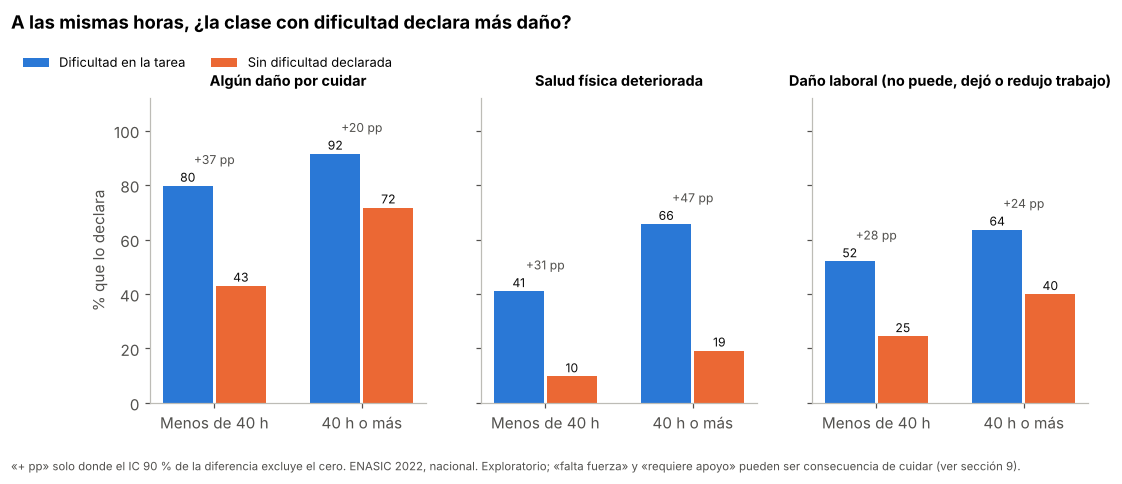

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (nombre_y, g) in zip(axs, estrato_h.groupby("desenlace", sort=False)):
    xs = np.arange(len(g))
    for i, (col, lado, etq) in enumerate([("con_dificultad", -0.18, "Dificultad en la tarea"),
                                          ("sin_dificultad", 0.18, "Sin dificultad declarada")]):
        ax.bar(xs + lado, g[col], width=0.34, color=COL[i], label=etq)
        for x0, v in zip(xs + lado, g[col]):
            ax.text(x0, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=TINTA)
    for x0, (_, r) in zip(xs, g.iterrows()):
        if r.significativa:
            ax.text(x0, max(r.con_dificultad, r.sin_dificultad) + 8, f"+{r.dif_pp:.0f} pp", ha="center", fontsize=8, color=TINTA2)
    ax.set_xticks(xs, g.horas); ax.set_title(nombre_y, fontsize=9.5, pad=8); ax.set_ylim(0, 112); ax.set_yticks(range(0, 101, 20))
axs[0].set_ylabel("% que lo declara")
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, fontsize=8.5, ncol=2, loc="upper left", bbox_to_anchor=(0.01, 1.02))
fig.suptitle("A las mismas horas, ¿la clase con dificultad declara más daño?", x=0.01, y=1.10, ha="left", fontweight="bold")
fig.text(0.01, -0.06, "«+ pp» solo donde el IC 90 % de la diferencia excluye el cero. ENASIC 2022, nacional. Exploratorio; "
         "«falta fuerza» y «requiere apoyo» pueden ser consecuencia de cuidar (ver sección 9).", fontsize=7.5, color=TINTA2)
fig.savefig(FIG / "f30_seg_dano_por_horas.png"); plt.show()

### Control de confusión: ¿la diferencia es solo «a quién cuida»?
El 82 % de la clase «Dificultad en la tarea» cuida a una persona con discapacidad (56 % en el total; sección 7). Si la diferencia de daño viniera solo del bloque, la clase no aportaría nada. Se repite la comparación **dentro de cada bloque × nivel de horas**. Las celdas con menos de 30 casos de muestra se marcan como no interpretables.

In [16]:
bh = []
for nombre_b, dom_b in [("Bloque discapacidad", DISC), ("Solo 60+ sin discapacidad", ~DISC)]:
    for nombre_h, dom_h in [("Menos de 40 h", ~ALTA), ("40 h o más", ALTA)]:
        for nombre_y in ["Algún daño por cuidar", "Salud física deteriorada"]:
            y = DESENLACES[nombre_y]
            yy = np.where(dom_b & dom_h, y, np.nan)
            f1 = fila(yy, dif_c); f0 = fila(yy, ~dif_c)
            d, dli, dls = dif_resto(yy, dif_c)
            bh.append(dict(bloque=nombre_b, horas=nombre_h, desenlace=nombre_y,
                           con_dificultad=f1["pct"], n_con=f1["n_muestra"], sin_dificultad=f0["pct"], n_sin=f0["n_muestra"],
                           dif_pp=d, dif_li90=dli, dif_ls90=dls, significativa=(dli > 0) or (dls < 0),
                           interpretable=min(f1["n_muestra"], f0["n_muestra"]) >= 30))
bh = pd.DataFrame(bh)
display(bh.round(1))
bh.round(3).to_csv(RES / "23_seg_dano_por_bloque_horas.csv", index=False, encoding="utf-8-sig")

,bloque,horas,desenlace,con_dificultad,n_con,sin_dificultad,n_sin,dif_pp,dif_li90,dif_ls90,significativa,interpretable
0,Bloque discapacidad,Menos de 40 h,Algún daño por cuidar,81.6,133,55.7,242,26.0,17.0,34.9,True,True
1,Bloque discapacidad,Menos de 40 h,Salud física deteriorada,46.0,133,16.7,242,29.3,17.9,40.8,True,True
2,Bloque discapacidad,40 h o más,Algún daño por cuidar,92.2,120,75.7,141,16.4,6.0,26.9,True,True
3,Bloque discapacidad,40 h o más,Salud física deteriorada,65.6,120,19.4,141,46.2,35.3,57.1,True,True
4,Solo 60+ sin discapacidad,Menos de 40 h,Algún daño por cuidar,74.3,43,32.3,256,41.9,26.9,57.0,True,True
5,Solo 60+ sin discapacidad,Menos de 40 h,Salud física deteriorada,26.6,43,3.9,256,22.7,12.9,32.5,True,True
6,Solo 60+ sin discapacidad,40 h o más,Algún daño por cuidar,84.8,17,67.8,91,16.9,-0.4,34.3,False,False
7,Solo 60+ sin discapacidad,40 h o más,Salud física deteriorada,67.3,17,19.1,91,48.2,22.5,74.0,True,False


## 8. Comparación contra alternativas simples (fuera de muestra)
Para cada segmentación y cada desenlace: se arma en entrenamiento el % ponderado de cada grupo, se predice ese % a las personas de prueba y se mide el error cuadrático (Brier) ponderado. **Mejora = 1 − Brier / Brier del promedio general** (en % ; 0 = no separa nada).
Particiones: 5 grupos de UPM × 20 repeticiones. El modelo de clases se reajusta en cada entrenamiento (tolerancia 1e-6, 5 arranques, por costo de cómputo).

Segmentaciones:
- **Intensidad (3)**: <20, 20–39, 40+ h (script 12).
- **Bloque × 40 h (4)**: a quién cuida × regla de 40 h.
- **Regla de dificultad (2)**: «declara 2 o más de 4 dificultades» (fuerza, no coopera, capacitación, requiere apoyo), escrita a mano para imitar la clase 1.
- **Regla de dificultad + 40 h (3)**: dificultad / sin dificultad y 40 h o más / resto, para imitar la solución de 3 clases.
- **Clases latentes k = 2 y k = 3.**

In [17]:
ndif = X[["fuerza", "nocoopera", "capacitacion", "reqapoyo"]].fillna(0).sum(1).values
REGLAS = {
    "Intensidad (3)": pd.cut(HORAS, [0, 19.99, 39.99, 1e9], labels=False),
    "Bloque × 40 h (4)": DISC.astype(int) * 2 + ALTA.astype(int),
    "Regla de dificultad (2)": (ndif >= 2).astype(int),
    "Regla de dificultad + 40 h (3)": np.where(ndif >= 2, 0, np.where(ALTA, 1, 2)),
}
Y_CV = {k: v for k, v in DESENLACES.items() if k in [
    "Algún daño por cuidar", "Salud física deteriorada", "Daño laboral (no puede, dejó o redujo trabajo)",
    "Insatisfecha con su tiempo libre", "«No tuve necesidad» de buscar (P6.45.09)",
    "No contrataría a nadie (P6.46)", "Acepta institución «solo unas horas» (P7.8)"]}


def brier_grupos(g_tr, g_te, y_tr, y_te, w_tr, w_te):
    ok_tr = ~np.isnan(y_tr); ok_te = ~np.isnan(y_te)
    pbar = np.average(y_tr[ok_tr], weights=w_tr[ok_tr])
    pred = np.full(len(y_te), pbar)
    for gval in np.unique(g_tr):
        m = (g_tr == gval) & ok_tr
        if w_tr[m].sum() > 0:
            pred[g_te == gval] = np.average(y_tr[m], weights=w_tr[m])
    b = np.average((y_te[ok_te] - pred[ok_te]) ** 2, weights=w_te[ok_te])
    b0 = np.average((y_te[ok_te] - pbar) ** 2, weights=w_te[ok_te])
    return b, b0


rng = np.random.default_rng(SEMILLA + 1)
upms_unicas = np.unique(UPM)
cv_filas = []
for rep in range(20):
    perm = rng.permutation(upms_unicas)
    pliegue = pd.Series(np.arange(len(perm)) % 5, index=perm)
    f_persona = pd.Series(UPM).map(pliegue).values
    for f in range(5):
        tr = f_persona != f; te = ~tr
        segs = {n: (g[tr], g[te]) for n, g in REGLAS.items()}
        for k in (2, 3):
            m = lca_fit(XA[tr], WN[tr] / WN[tr].mean(), k, n_init=5, tol=1e-6, max_iter=500, seed=SEMILLA + rep * 10 + f)
            segs[f"Clases latentes (k = {k})"] = (lca_posterior(m, XA[tr]).argmax(1), lca_posterior(m, XA[te]).argmax(1))
        for ny, y in Y_CV.items():
            for ns, (gtr, gte) in segs.items():
                b, b0 = brier_grupos(gtr, gte, y[tr], y[te], WN[tr], WN[te])
                cv_filas.append(dict(rep=rep, pliegue=f, desenlace=ny, segmentacion=ns, brier=b, brier0=b0))
cv = pd.DataFrame(cv_filas)
agg = cv.groupby(["desenlace", "segmentacion", "rep"])[["brier", "brier0"]].sum().reset_index()
agg["mejora_pct"] = 100 * (1 - agg.brier / agg.brier0)
comp = agg.groupby(["desenlace", "segmentacion"]).mejora_pct.agg(
    mejora_media="mean", p05=lambda s: s.quantile(0.05), p95=lambda s: s.quantile(0.95)).reset_index()
orden_seg = list(REGLAS) + ["Clases latentes (k = 2)", "Clases latentes (k = 3)"]
tabla_comp = comp.pivot(index="desenlace", columns="segmentacion", values="mejora_media")[orden_seg]
display(tabla_comp.round(2))


# Diferencias pareadas por repetición: clases latentes contra su regla equivalente
def pareada(a, b):
    p = agg.pivot_table(index=["desenlace", "rep"], columns="segmentacion", values="mejora_pct").reset_index()
    p["dif"] = p[a] - p[b]
    return p.groupby("desenlace").dif.agg(dif_media="mean", p05=lambda s: s.quantile(0.05), p95=lambda s: s.quantile(0.95))

par2 = pareada("Clases latentes (k = 2)", "Regla de dificultad (2)").assign(comparacion="k=2 contra regla de dificultad (2)")
par3 = pareada("Clases latentes (k = 3)", "Regla de dificultad + 40 h (3)").assign(comparacion="k=3 contra regla de dificultad + 40 h (3)")
par4 = pareada("Regla de dificultad + 40 h (3)", "Intensidad (3)").assign(comparacion="regla de dificultad + 40 h contra intensidad (3)")
pareadas = pd.concat([par2, par3, par4]).reset_index()
display(pareadas.round(2))
comp.round(3).to_csv(RES / "23_seg_comparacion_cv.csv", index=False, encoding="utf-8-sig")
pareadas.round(3).to_csv(RES / "23_seg_comparacion_pareada.csv", index=False, encoding="utf-8-sig")

/tmp/ipykernel_439/2143446093.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ndif = X[["fuerza", "nocoopera", "capacitacion", "reqapoyo"]].fillna(0).sum(1).values


segmentacion,Intensidad (3),Bloque × 40 h (4),Regla de dificultad (2),Regla de dificultad + 40 h (3),Clases latentes (k = 2),Clases latentes (k = 3)
desenlace,,,,,,
Acepta institución «solo unas horas» (P7.8),-0.51,0.91,-0.08,-0.47,-0.19,-0.82
Algún daño por cuidar,7.00,11.23,7.21,13.62,7.36,13.32
"Daño laboral (no puede, dejó o redujo trabajo)",2.97,6.54,4.76,6.48,5.09,6.35
Insatisfecha con su tiempo libre,-0.85,-1.35,1.23,0.92,2.02,2.46
No contrataría a nadie (P6.46),0.46,-0.13,0.51,1.46,0.32,0.85
Salud física deteriorada,2.86,6.15,16.00,16.46,15.56,15.67
«No tuve necesidad» de buscar (P6.45.09),-0.78,-1.29,-0.15,0.43,-0.38,-0.87


,desenlace,dif_media,p05,p95,comparacion
0,Acepta institución «solo unas horas» (P7.8),-0.11,-0.30,0.09,k=2 contra regla de dificultad (2)
1,Algún daño por cuidar,0.15,-0.88,0.90,k=2 contra regla de dificultad (2)
2,"Daño laboral (no puede, dejó o redujo trabajo)",0.34,-0.49,0.98,k=2 contra regla de dificultad (2)
3,Insatisfecha con su tiempo libre,0.79,0.15,1.70,k=2 contra regla de dificultad (2)
4,No contrataría a nadie (P6.46),-0.19,-0.63,0.24,k=2 contra regla de dificultad (2)
5,Salud física deteriorada,-0.44,-1.77,0.44,k=2 contra regla de dificultad (2)
6,«No tuve necesidad» de buscar (P6.45.09),-0.23,-0.43,0.00,k=2 contra regla de dificultad (2)
7,Acepta institución «solo unas horas» (P7.8),-0.35,-0.97,0.40,k=3 contra regla de dificultad + 40 h (3)
8,Algún daño por cuidar,-0.31,-1.58,1.76,k=3 contra regla de dificultad + 40 h (3)
9,"Daño laboral (no puede, dejó o redujo trabajo)",-0.12,-1.41,1.05,k=3 contra regla de dificultad + 40 h (3)


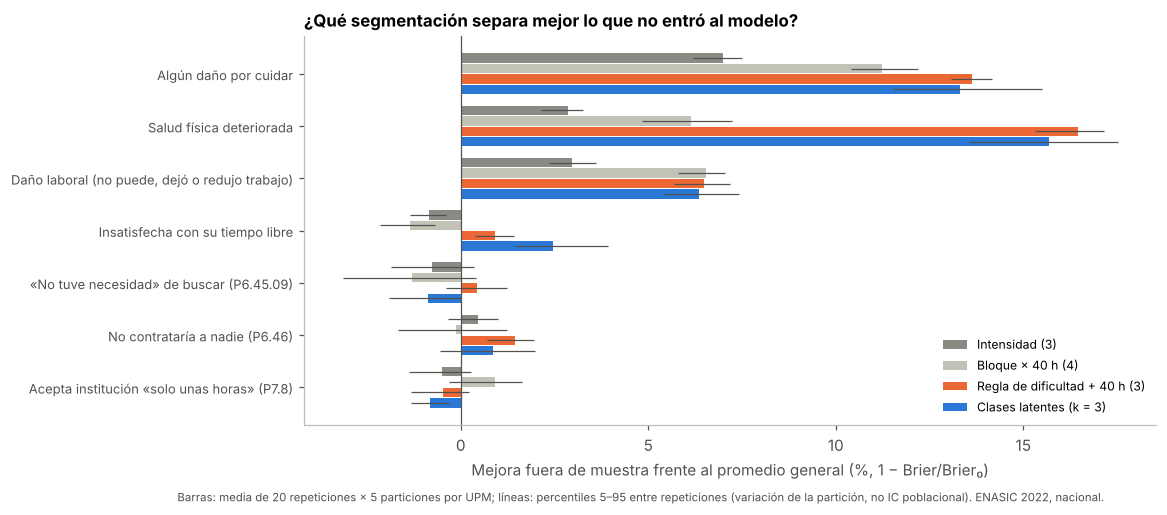

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.6))
des = list(Y_CV)
segs_fig = ["Intensidad (3)", "Bloque × 40 h (4)", "Regla de dificultad + 40 h (3)", "Clases latentes (k = 3)"]
colores = [GRIS, "#c3c2b7", COL[1], COL[0]]
hgt = 0.2
for i, s in enumerate(segs_fig):
    sub = comp[comp.segmentacion == s].set_index("desenlace").loc[des]
    ys = np.arange(len(des)) + (i - 1.5) * hgt
    ax.barh(ys, sub.mejora_media, height=hgt * 0.9, color=colores[i], label=s)
    ax.errorbar(sub.mejora_media, ys, xerr=[sub.mejora_media - sub.p05, sub.p95 - sub.mejora_media],
                fmt="none", ecolor=TINTA2, elinewidth=0.8, capsize=0)
ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_yticks(np.arange(len(des)), des, fontsize=8.5); ax.invert_yaxis()
ax.set_xlabel("Mejora fuera de muestra frente al promedio general (%, 1 − Brier/Brier₀)")
ax.set_title("¿Qué segmentación separa mejor lo que no entró al modelo?", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.text(0.01, -0.04, "Barras: media de 20 repeticiones × 5 particiones por UPM; líneas: percentiles 5–95 entre repeticiones "
         "(variación de la partición, no IC poblacional). ENASIC 2022, nacional.", fontsize=7.5, color=TINTA2)
fig.savefig(FIG / "f31_seg_comparacion.png"); plt.show()

## 9. Sensibilidad
1. **Sin «le falta fuerza física» ni «requiere apoyo»** (posibles consecuencias de cuidar): ¿sigue apareciendo una clase de dificultad y sigue separando el daño a igual horas?
2. **Incertidumbre de la asignación**: daño por clase ponderando por la probabilidad posterior en vez de asignar a la clase más probable.

In [19]:
cols_sin = [c for c in X.columns if c not in ("fuerza", "reqapoyo")]
XS = X[cols_sin].fillna(-1).astype(int).values
sens = []
for k in (2, 3):
    ms = lca_fit(XS, WN, k)
    lab_s = ms["resp"].argmax(1)
    sens.append(dict(variante="sin fuerza ni requiere apoyo", k=k, BIC=ms["bic"], entropia=ms["entropia"],
                     ARI_contra_principal=adjusted_rand_score(asignar(k), lab_s)))
    j_cap = cols_sin.index("capacitacion")
    c_dif = int(np.argmax(ms["theta"][j_cap][:, 1]))
    dom = lab_s == c_dif
    for nombre_h, dom_h in [("Menos de 40 h", ~ALTA), ("40 h o más", ALTA)]:
        for ny in ["Algún daño por cuidar", "Salud física deteriorada"]:
            yy = np.where(dom_h, DESENLACES[ny], np.nan)
            d, dli, dls = dif_resto(yy, dom)
            sens.append(dict(variante="sin fuerza ni requiere apoyo", k=k, clase="mayor necesidad de capacitación",
                             pct_clase=fila(dom.astype(float))["pct"], horas=nombre_h, desenlace=ny,
                             dif_pp=d, dif_li90=dli, dif_ls90=dls, significativa=(dli > 0) or (dls < 0)))
sens = pd.DataFrame(sens)
display(sens.round(3))

# Asignación suave: proporciones ponderadas por la probabilidad posterior
suave = []
for k in (K, K_ALT):
    R = modelos[k]["resp"]
    for c in range(k):
        for ny in ["Algún daño por cuidar", "Salud física deteriorada", "Daño laboral (no puede, dejó o redujo trabajo)"]:
            y = DESENLACES[ny]
            ok = ~np.isnan(y)
            p_suave = 100 * np.average(y[ok], weights=(W * R[:, c])[ok])
            p_dura = val[(val.k == k) & (val.clase == c + 1) & (val.indicador == ny)].pct.item()
            suave.append(dict(k=k, clase=c + 1, nombre=nombre_clases(k)[c], desenlace=ny,
                              pct_asignacion_maxima=p_dura, pct_asignacion_suave=p_suave))
suave = pd.DataFrame(suave)
display(suave.round(1))
pd.concat([sens.assign(prueba="sin_fuerza_ni_apoyo"), suave.assign(prueba="asignacion_suave")]).round(3).to_csv(
    RES / "23_seg_sensibilidad.csv", index=False, encoding="utf-8-sig")

,variante,k,BIC,entropia,ARI_contra_principal,clase,pct_clase,horas,desenlace,dif_pp,dif_li90,dif_ls90,significativa
0,sin fuerza ni requiere apoyo,2,8013.824,0.583,0.296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,sin fuerza ni requiere apoyo,2,NaN,NaN,NaN,mayor necesidad de capacitación,17.094,Menos de 40 h,Algún daño por cuidar,21.410,10.550,32.270,True
2,sin fuerza ni requiere apoyo,2,NaN,NaN,NaN,mayor necesidad de capacitación,17.094,Menos de 40 h,Salud física deteriorada,33.239,21.945,44.532,True
3,sin fuerza ni requiere apoyo,2,NaN,NaN,NaN,mayor necesidad de capacitación,17.094,40 h o más,Algún daño por cuidar,14.495,4.141,24.850,True
4,sin fuerza ni requiere apoyo,2,NaN,NaN,NaN,mayor necesidad de capacitación,17.094,40 h o más,Salud física deteriorada,33.193,19.175,47.211,True
5,sin fuerza ni requiere apoyo,3,8004.797,0.509,0.433,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,sin fuerza ni requiere apoyo,3,NaN,NaN,NaN,mayor necesidad de capacitación,14.484,Menos de 40 h,Algún daño por cuidar,18.736,7.511,29.962,True
7,sin fuerza ni requiere apoyo,3,NaN,NaN,NaN,mayor necesidad de capacitación,14.484,Menos de 40 h,Salud física deteriorada,28.373,17.103,39.644,True
8,sin fuerza ni requiere apoyo,3,NaN,NaN,NaN,mayor necesidad de capacitación,14.484,40 h o más,Algún daño por cuidar,24.907,19.037,30.778,True
9,sin fuerza ni requiere apoyo,3,NaN,NaN,NaN,mayor necesidad de capacitación,14.484,40 h o más,Salud física deteriorada,44.682,31.773,57.591,True


,k,clase,nombre,desenlace,pct_asignacion_maxima,pct_asignacion_suave
0,2,1,Dificultad en la tarea,Algún daño por cuidar,85.2,81.7
1,2,1,Dificultad en la tarea,Salud física deteriorada,52.5,47.1
2,2,1,Dificultad en la tarea,"Daño laboral (no puede, dejó o redujo trabajo)",57.4,53.3
3,2,2,Sin dificultad declarada,Algún daño por cuidar,54.2,54.3
4,2,2,Sin dificultad declarada,Salud física deteriorada,13.4,13.9
5,2,2,Sin dificultad declarada,"Daño laboral (no puede, dejó o redujo trabajo)",30.5,31.0
6,3,1,Dificultad en la tarea,Algún daño por cuidar,85.3,82.5
7,3,1,Dificultad en la tarea,Salud física deteriorada,53.0,48.1
8,3,1,Dificultad en la tarea,"Daño laboral (no puede, dejó o redujo trabajo)",57.2,54.2
9,3,2,Alta intensidad sin dificultad,Algún daño por cuidar,70.7,69.9


## 10. Exportar agregados
Solo porcentajes, IC y conteos de muestra por clase. **Ninguna clase por persona sale del notebook.**

In [20]:
perf.round(3).to_csv(RES / "23_seg_perfiles.csv", index=False, encoding="utf-8-sig")
val.round(3).to_csv(RES / "23_seg_validacion.csv", index=False, encoding="utf-8-sig")
print("Archivos escritos:")
for f in sorted(RES.glob("23_seg_*.csv")):
    print("  ", f)
for f in sorted(FIG.glob("f2[7-9]_seg_*.png")) + sorted(FIG.glob("f3[01]_seg_*.png")):
    print("  ", f)

Archivos escritos:
   resultados/23_seg_comparacion_cv.csv
   resultados/23_seg_comparacion_pareada.csv
   resultados/23_seg_dano_por_bloque_horas.csv
   resultados/23_seg_dano_por_horas.csv
   resultados/23_seg_dificultad_fuera_regla.csv
   resultados/23_seg_perfiles.csv
   resultados/23_seg_seleccion_k.csv
   resultados/23_seg_sensibilidad.csv
   resultados/23_seg_validacion.csv
   figuras/f27_seg_seleccion_k.png
   figuras/f28_seg_perfiles_k2.png
   figuras/f29_seg_perfiles_k3.png
   figuras/f30_seg_dano_por_horas.png
   figuras/f31_seg_comparacion.png


## 11. Lectura (generada con las cifras de arriba)

In [21]:
t2 = perf[(perf.k == K) & (perf.variable == "tamano")].set_index("clase")
v2 = val[val.k == K].set_index(["indicador", "clase"])
ari_k = sel.set_index("k")
eh = estrato_h.set_index(["horas", "desenlace"])
pc_ = comp.set_index(["desenlace", "segmentacion"]).mejora_media
print(f"""1. Estructura. Con {K} clases el modelo es estable (ARI mediano {ari_k.loc[K,'ARI_mediana']:.2f}); con 3 clases
   la partición cambia mucho entre réplicas (ARI mediano {ari_k.loc[3,'ARI_mediana']:.2f}). Solo una división es robusta.
2. La división robusta no es por horas: la clase «Dificultad en la tarea» ({t2.loc[1,'pct']:.1f}% de las cuidadoras,
   IC {t2.loc[1,'li90']:.1f}–{t2.loc[1,'ls90']:.1f}; ≈ {t2.loc[1,'total_expandido']:,.0f} personas) tiene casi la misma
   distribución de horas que el resto. La definen falta de fuerza, necesidad de capacitación y necesitar a otra persona.
3. A las mismas horas declara más daño: con menos de 40 h, algún daño {eh.loc[('Menos de 40 h','Algún daño por cuidar'),'con_dificultad']:.0f}%
   contra {eh.loc[('Menos de 40 h','Algún daño por cuidar'),'sin_dificultad']:.0f}% (dif. {eh.loc[('Menos de 40 h','Algún daño por cuidar'),'dif_pp']:.0f} pp,
   IC {eh.loc[('Menos de 40 h','Algún daño por cuidar'),'dif_li90']:.0f} a {eh.loc[('Menos de 40 h','Algún daño por cuidar'),'dif_ls90']:.0f}).
   {f_fuera['pct']:.1f}% del universo tiene dificultad en la tarea y cuida menos de 40 h: la regla de 40 h no la ve.
   Se sostiene dentro de cada bloque del cuestionario (no es solo «a quién cuida»): con menos de 40 h, algún daño
   +{bh.query("bloque=='Bloque discapacidad' and horas=='Menos de 40 h' and desenlace=='Algún daño por cuidar'").dif_pp.item():.0f} pp en el bloque de discapacidad y
   +{bh.query("bloque=='Solo 60+ sin discapacidad' and horas=='Menos de 40 h' and desenlace=='Algún daño por cuidar'").dif_pp.item():.0f} pp en el de solo 60+.
4. El modelo no le gana a una regla escrita a mano: «2 o más de 4 dificultades» separa los desenlaces igual que las
   clases latentes (diferencias pareadas menores a 1 punto). Lo que agrega información es la dimensión de dificultad,
   no el algoritmo: sumarla a la regla de 40 h mejora la separación de algún daño de {pc_.loc[('Algún daño por cuidar','Intensidad (3)')]:.1f}% a
   {pc_.loc[('Algún daño por cuidar','Regla de dificultad + 40 h (3)')]:.1f}% y la de salud física de {pc_.loc[('Salud física deteriorada','Intensidad (3)')]:.1f}% a
   {pc_.loc[('Salud física deteriorada','Regla de dificultad + 40 h (3)')]:.1f}%.
5. Las clases no separan la búsqueda de servicios, «no tuve necesidad» ni la aceptación de «unas horas»: la norma
   familiar es parecida en todos los perfiles.""")

1. Estructura. Con 2 clases el modelo es estable (ARI mediano 0.91); con 3 clases
   la partición cambia mucho entre réplicas (ARI mediano 0.66). Solo una división es robusta.
2. La división robusta no es por horas: la clase «Dificultad en la tarea» (25.7% de las cuidadoras,
   IC 22.1–29.3; ≈ 1,598,759 personas) tiene casi la misma
   distribución de horas que el resto. La definen falta de fuerza, necesidad de capacitación y necesitar a otra persona.
3. A las mismas horas declara más daño: con menos de 40 h, algún daño 80%
   contra 43% (dif. 37 pp,
   IC 29 a 44).
   13.8% del universo tiene dificultad en la tarea y cuida menos de 40 h: la regla de 40 h no la ve.
   Se sostiene dentro de cada bloque del cuestionario (no es solo «a quién cuida»): con menos de 40 h, algún daño
   +26 pp en el bloque de discapacidad y
   +42 pp en el de solo 60+.
4. El modelo no le gana a una regla escrita a mano: «2 o más de 4 dificultades» separa los desenlaces igual que las
   clases latentes (difere

## 12. Qué permite y qué no permite afirmar
**Permite:** que entre las personas que cuidan a alguien con discapacidad o de 60+ hay una dimensión de «dificultad en la tarea» distinta de las horas, estable en el remuestreo, que a igual horas va con más daño declarado; y que una regla de pocas preguntas la capta igual que el modelo.

**No permite:**
- Nada sobre la CDMX: la ENASIC es nacional.
- Que la dificultad *cause* el daño. Es una encuesta transversal y dificultad y daño se reportan en la misma entrevista; parte de la asociación puede ser estilo de respuesta. «Le falta fuerza física» se parece a «salud física deteriorada».
- Que un formato de apoyo (capacitación, segunda persona, relevo) funcione para una clase. Eso solo lo puede medir el piloto.
- Que existan «tipos» de cuidadoras. Hay una división estable en dos; tres o más clases no son estables.
- Que la segmentación mejore la focalización. A un mismo cupo, los notebooks 21 y 22 ya mostraron que añadir estas variables no supera a la regla de 40 h en cobertura de «algún daño». La segmentación informa **qué ofrecer**, no **a quién priorizar**.

**Deja de funcionar si:** las dificultades no se preguntan igual a todas las personas (en la ENASIC sí se preguntan en los dos bloques, a diferencia de las actividades básicas); se aplica a cuidadoras de menores sin discapacidad (fuera del universo); o se usa la clase de una persona para negarle un apoyo, porque la asignación individual es incierta (entropía de la solución elegida en la tabla de la sección 5, lejos de 1).